# Experiment 6: Gradient Descent for Weight Updates

**Aim:** To apply Gradient Descent for updating the weights of a simple neural network during training.

**Theory:**

Gradient Descent is an optimisation algorithm used to minimise a loss function by iteratively updating parameters (weights and bias) in the direction opposite to the gradient of the loss with respect to those parameters:

$$w = w - \eta \frac{\partial L}{\partial w}, \qquad b = b - \eta \frac{\partial L}{\partial b}$$

This notebook trains a single neuron (linear combination + sigmoid output) using Mean Squared Error loss and manually derived gradients, and plots how the loss decreases over training epochs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

### Prepare the dataset (logical OR) and initialise parameters

In [2]:
np.random.seed(1)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 1], dtype=float)  # logical OR

weights = np.random.uniform(-1, 1, X.shape[1])
bias = 0.0
learning_rate = 0.5
epochs = 2000
loss_history = []

### Train using Gradient Descent

In [3]:
for epoch in range(epochs):
    # Forward pass
    z = np.dot(X, weights) + bias
    predictions = sigmoid(z)

    # Mean Squared Error loss
    error = predictions - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Gradients (chain rule)
    d_pred = 2 * error * predictions * (1 - predictions)
    d_weights = np.dot(X.T, d_pred) / len(X)
    d_bias = np.mean(d_pred)

    # Gradient Descent update
    weights -= learning_rate * d_weights
    bias -= learning_rate * d_bias

    if epoch % 400 == 0:
        print(f"Epoch {epoch:4d} - Loss: {loss:.6f}")

print(f"\nFinal Loss: {loss_history[-1]:.6f}")
print("Final weights:", weights)
print("Final bias   :", bias)

Epoch    0 - Loss: 0.220715
Epoch  400 - Loss: 0.017963
Epoch  800 - Loss: 0.008199
Epoch 1200 - Loss: 0.005158
Epoch 1600 - Loss: 0.003722

Final Loss: 0.002898
Final weights: [5.37024349 5.37060191]
Final bias   : -2.4301313686420705


### Predictions after training

In [4]:
final_preds = sigmoid(np.dot(X, weights) + bias)
for xi, p, target in zip(X, final_preds, y):
    print(f"Input: {xi} -> Predicted: {p:.4f} -> Rounded: {round(p)} | Actual: {int(target)}")

Input: [0. 0.] -> Predicted: 0.0809 -> Rounded: 0 | Actual: 0
Input: [0. 1.] -> Predicted: 0.9498 -> Rounded: 1 | Actual: 1
Input: [1. 0.] -> Predicted: 0.9498 -> Rounded: 1 | Actual: 1
Input: [1. 1.] -> Predicted: 0.9998 -> Rounded: 1 | Actual: 1


### Plot the loss curve

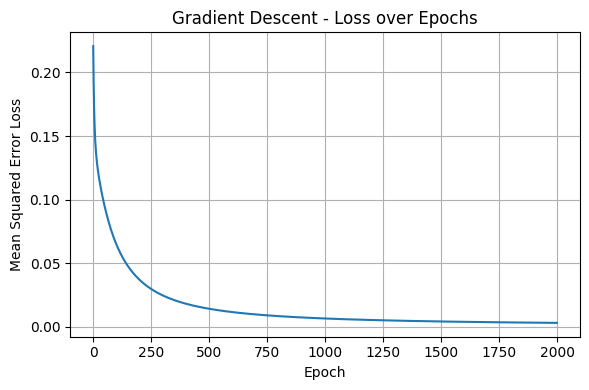

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.title("Gradient Descent - Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("gradient_descent_loss.png", dpi=150)
plt.show()

### Conclusion
The loss decreases smoothly and monotonically as gradient descent iteratively adjusts the weights and bias, and the trained neuron correctly learns the OR function.